# Signals FBG

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import xarray as xr
from tqdm import tqdm
import glob
from scipy import signal
from numpy.lib.stride_tricks import sliding_window_view
from obspy.signal.filter import highpass, bandpass, lowpass
from obspy.signal.invsim import cosine_taper
from scipy.signal import spectrogram, detrend
from obspy.signal.trigger import classic_sta_lta, plot_trigger,trigger_onset
import obspy
import os
from itertools import combinations

In [2]:
def preprocess(ds):
    dsnew = ds.copy()
    dsnew = dsnew.resample(Time = '5s').median()

    return dsnew

In [3]:
plot_dir = '../../plots/recurrent_events'
if not os.path.exists(plot_dir):
    os.makedirs(plot_dir)

In [26]:
data_dir = '../../data/gridsearch'
if not os.path.exists(data_dir):
    os.makedirs(data_dir)

## Processing

### Importing the data

In [4]:
ncfiles = glob.glob('/mnt/ICELAND_2024/GUNNUVHER/FBG/LowFreqSampling/aligned_nc_converted/FBG_*nc')#+glob.glob('/mnt/ICELAND_2024/GUNNUVHER/FBG/LowFreqSampling/aligned_nc_converted/FBG_2025.02*nc')
ncfiles.sort()
for i, file in enumerate(tqdm(ncfiles)) : 
    ds = xr.open_dataset(file)
    ds = ds.drop_vars(['relative_Time', 'Temperature_calibration','Strain_calibration'])
    #ds = preprocess(ds)
    ds = ds.sel(Channel=2)
    if i == 0 :
        dsch_hstrain = ds.copy()
        continue
    dsch_hstrain = xr.concat([dsch_hstrain, ds], dim='Time')

100%|██████████| 347/347 [01:57<00:00,  2.96it/s]


### Cleaning

In [5]:
rng = np.arange(dsch_hstrain.Time.values[0], dsch_hstrain.Time.values[-1], 2, dtype='datetime64[s]')
dsch_hstrain = dsch_hstrain.sortby('Time')
dsch_hstrain = dsch_hstrain.drop_duplicates('Time')
dsch_hstrain = dsch_hstrain.reindex({'Time': rng}, method='nearest', tolerance=np.timedelta64(2, 's'))

/tmp/ipykernel_451001/2068137241.py:4: UserWarning: Converting non-nanosecond precision datetime values to nanosecond precision. This behavior can eventually be relaxed in xarray, as it is an artifact from pandas which is now beginning to support non-nanosecond precision values. This warning is caused by passing non-nanosecond np.datetime64 or np.timedelta64 values to the DataArray or Variable constructor; it can be silenced by converting the values to nanosecond precision ahead of time.
  dsch_hstrain = dsch_hstrain.reindex({'Time': rng}, method='nearest', tolerance=np.timedelta64(2, 's'))


### Detrend

In [6]:
def _detrend_ufunc(x) :
    med = np.nanmedian(x)#, axis=1).reshape(-1,1)
    dtrend = x - med
    dtrend = np.where(dtrend > 1, np.nan, dtrend)
    return dtrend

def detrend_signal(x) :
    return xr.apply_ufunc(_detrend_ufunc, x)

### Plot the third FBG in strain-rate

In [7]:
svv = dsch_hstrain.sel(FBG=3)

In [8]:
dtrend = detrend_signal(svv)

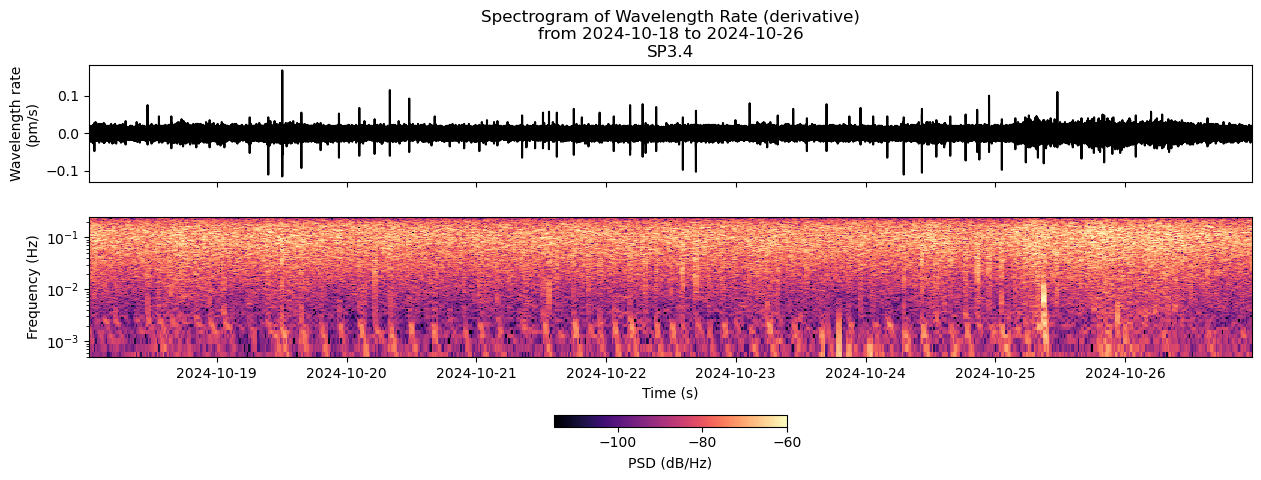

In [9]:
%matplotlib inline
fig, ax = plt.subplots(figsize=(15,5), nrows=2, sharex=True, gridspec_kw={'height_ratios':[1,2]})
fig.patch.set_alpha(0)
ax[0].plot(dtrend.sel(Time=slice('2024-10-18', '2024-10-26')).Time, np.gradient(dtrend.sel(Time=slice('2024-10-18', '2024-10-26')).Wavelength_nm.values*1000, 2), color='k')
ax[0].set_ylabel('Wavelength rate\n(pm/s)')

f,t,Sxx = spectrogram(np.gradient(dtrend.sel(Time=slice('2024-10-18', '2024-10-26')).Wavelength_nm.values*1000, 2), fs=1/2, nperseg=2000, noverlap=1500, scaling='spectrum')
im = ax[1].pcolormesh(t.astype(int) + dtrend.sel(Time=slice('2024-10-18', '2024-10-26')).Time.values[0].astype('datetime64[s]'), f, 10*np.log10(Sxx), shading='auto', cmap='magma', 
                      norm=mcolors.Normalize(vmin=-115, vmax=-60))
ax[1].set_ylabel('Frequency (Hz)')
ax[1].set_xlabel('Time (s)')
ax[1].set_yscale('log')
ax[1].set_ylim(5e-4, 0.25)
ax[0].set_facecolor('white')
ax[0].set_title('Spectrogram of Wavelength Rate (derivative)\nfrom 2024-10-18 to 2024-10-26\nSP3.4')
fig.colorbar(im, ax=ax[1], label='PSD (dB/Hz)', orientation='horizontal', shrink=.2, pad=0.25)
plt.savefig(plot_dir + '/spectrogram_signal_october.png', bbox_inches='tight')
plt.show()

## Take a look to end October

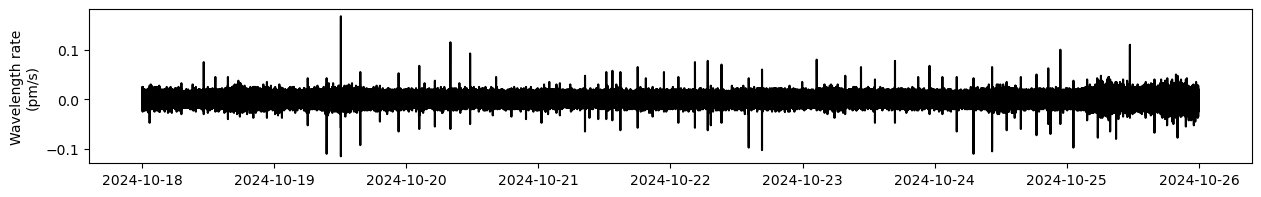

In [10]:
%matplotlib inline
plt.figure(figsize=(15,2))
plt.plot(dtrend.sel(Time=slice('2024-10-18', '2024-10-25')).Time, np.gradient(dtrend.Wavelength_nm.sel(Time=slice('2024-10-18', '2024-10-25')).values*1000, 2), color='k')
plt.ylabel('Wavelength rate\n(pm/s)')
plt.show()

In [11]:
st = obspy.Stream()
tr = obspy.Trace()
tr.stats.sampling_rate = 0.5
tr.stats.startdate = obspy.UTCDateTime(str(dtrend.sel(Time=slice('2024-10-18', '2024-10-25')).Time.values[0]))
tr.data = np.gradient(dtrend.Wavelength_nm.sel(Time=slice('2024-10-18', '2024-10-25')).values*1000, 2)
st.append(tr)

1 Trace(s) in Stream:
... | 1970-01-01T00:00:00.000000Z - 1970-01-08T23:59:58.000000Z | 0.5 Hz, 345600 samples

In [12]:
sta_lta = classic_sta_lta(tr.data, nsta=3, nlta=500)

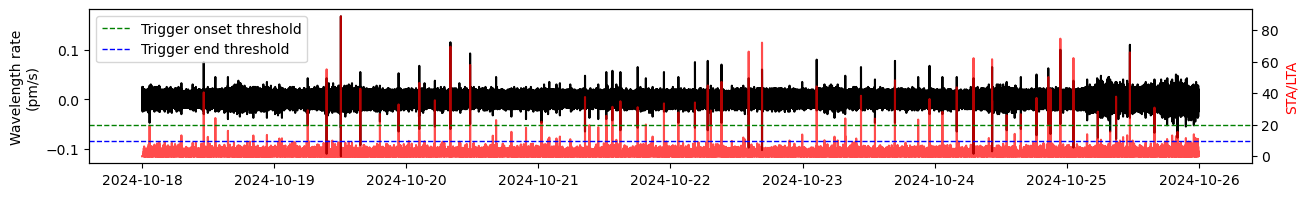

In [14]:
%matplotlib inline
fig, ax = plt.subplots(figsize=(15,2))
ax.plot(dtrend.sel(Time=slice('2024-10-18', '2024-10-25')).Time, np.gradient(dtrend.Wavelength_nm.sel(Time=slice('2024-10-18', '2024-10-25')).values*1000, 2), color='k')
axb=ax.twinx()
axb.plot(dtrend.sel(Time=slice('2024-10-18', '2024-10-25')).Time, sta_lta, color='r', alpha=0.7)
axb.axhline(20, color='g', linestyle='--', lw=1, label='Trigger onset threshold')
axb.axhline(10, color='b', linestyle='--', lw=1, label='Trigger end threshold')
axb.set_ylabel('STA/LTA', color='r')
ax.set_ylabel('Wavelength rate\n(pm/s)')
plt.legend()
plt.show()

In [15]:
triggers_sta_lta = trigger_onset(sta_lta, 20, 10)

In [16]:
events = []
for trigger in triggers_sta_lta :
    event = tr.data[trigger[0]-30:trigger[0]+60]
    events.append(event)

In [17]:
ref_event = events[0] - np.median(events[0])

In [19]:
_lags = []
_corr_2d = []
for i, event in enumerate(events) :
    correlation = signal.correlate(ref_event, event - np.mean(event), mode="full")
    lags = signal.correlation_lags(len(ref_event), len(event), mode="full")
    _corr_2d.append(correlation)
    lag = lags[np.argmin(correlation)]
    _lags.append(lag)

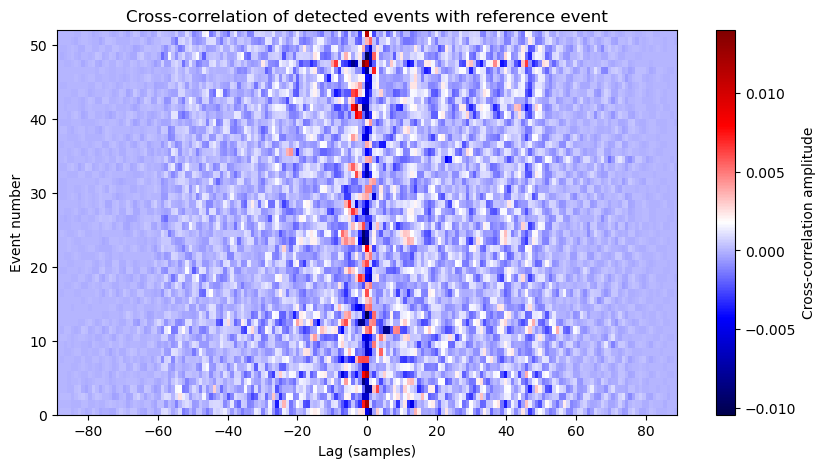

In [20]:
plt.figure(figsize=(10,5))
plt.imshow(_corr_2d, aspect='auto', cmap='seismic', extent=[min(lags), max(lags), 0, len(events)])
plt.colorbar(label='Cross-correlation amplitude')
plt.xlabel('Lag (samples)')
plt.ylabel('Event number')
plt.title('Cross-correlation of detected events with reference event')
plt.show()

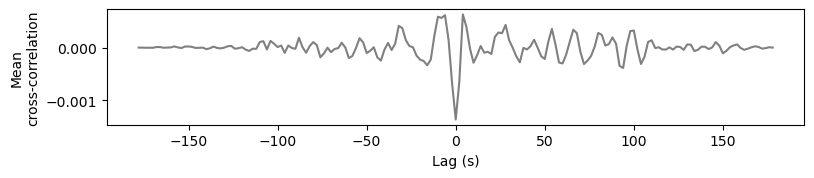

In [21]:
plt.figure(figsize=(9,1.5))
plt.plot(lags/.5, np.nanmean(_corr_2d, axis=0),c='grey')
plt.xlabel('Lag (s)')
plt.ylabel('Mean\ncross-correlation')
plt.show()

In [22]:
aligned_events = []
for i, event in enumerate(events) :
    lag = _lags[i]
    if lag > 0 :
        aligned_event = np.pad(event, (lag,0), mode='constant')[:len(ref_event)]
    elif lag < 0 :
        aligned_event = np.pad(event, (0,-lag), mode='constant')[-lag:len(ref_event)-lag]
    else :
        aligned_event = event
    aligned_events.append(aligned_event)

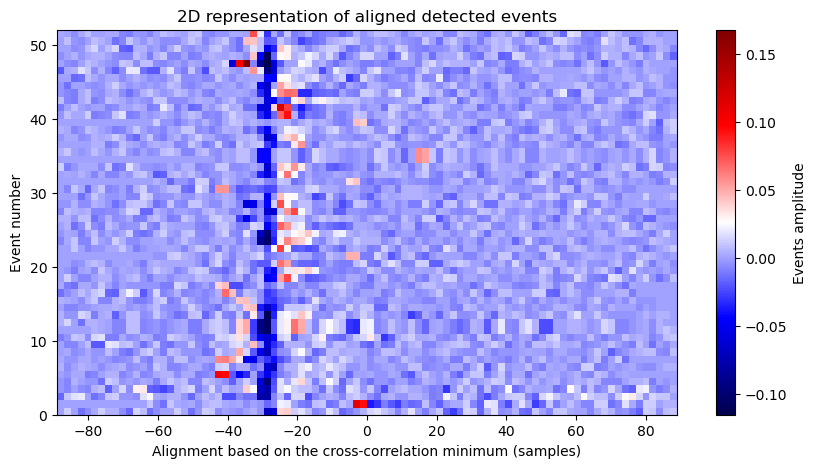

In [23]:
plt.figure(figsize=(10,5))
plt.imshow(aligned_events, aspect='auto', cmap='seismic', extent=[min(lags), max(lags), 0, len(events)])
plt.colorbar(label='Events amplitude')
plt.xlabel('Alignment based on the cross-correlation minimum (samples)')
plt.ylabel('Event number')
plt.title('2D representation of aligned detected events')
plt.show()

### Save the data

In [27]:
aligned_events = np.array(aligned_events)
np.save(data_dir+'/aligned_events.npy', aligned_events)

### Plotting the average and median curve for SP3.4

In [24]:
from obspy.signal.tf_misfit import cwt
from obspy.imaging.cm import obspy_sequential

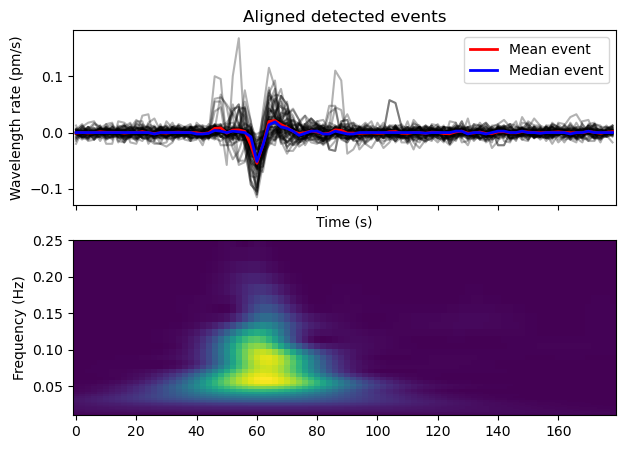

In [ ]:
%matplotlib inline
fig, ax = plt.subplots(figsize=(7,5), nrows=2, sharex=True)
time = np.arange(len(ref_event))*2  
for aligned_event in aligned_events :
    ax[0].plot(time, aligned_event, color='k', alpha=0.3)
ax[0].plot(time, np.mean(aligned_events, axis=0), color='r', lw=2, label='Mean event')
ax[0].plot(time, np.median(aligned_events, axis=0), color='b', lw=2, label='Median event')

fmin = 1e-4
fmax = .25
scalogram = cwt(np.mean(aligned_events, axis=0), 2, 8, fmin, fmax)
x, y = np.meshgrid(
    time,
    np.logspace(np.log10(fmin), np.log10(fmax), scalogram.shape[0]))

ax[1].pcolormesh(x, y, np.abs(scalogram), cmap='viridis', norm=mcolors.PowerNorm(gamma=1.7))
ax[1].set_ylim(1e-2, fmax)
ax[1].set_ylabel('Frequency (Hz)')
ax[0].set_xlabel('Time (s)')
#ax[1].set_yscale('log')
ax[0].legend()
ax[0].set_ylabel('Wavelength rate (pm/s)')
ax[0].set_title('Aligned detected events')
fig.patch.set_alpha(0)
ax[0].set_facecolor('white')
plt.savefig('./plots/aligned_events_october.png', bbox_inches='tight')
plt.show()

## Finding all the events for every strain-pads

In [ ]:
dtrend_october = detrend_signal(dsch_hstrain.sel(Time=slice('2024-10-19', '2024-10-25'), FBG=slice(0,6)))
grad = np.gradient(dtrend_october.Wavelength_nm, axis=1)

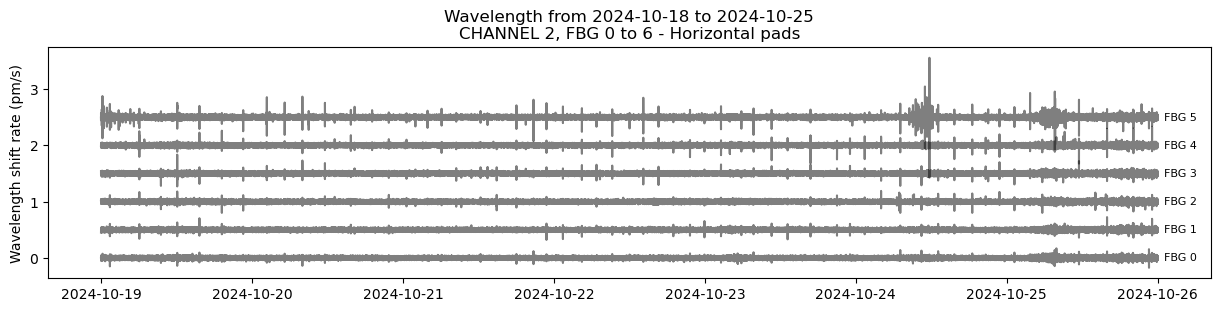

In [ ]:
%matplotlib inline
#filt_grad = np.zeros_like(grad)
#for i in range(grad.shape[1]) :
#    filt_grad[:,i] = signal.medfilt(grad[:,i], kernel_size=3)
plt.figure(figsize=(15,3))
for i in range(grad.shape[0]):
    plt.plot(dtrend_october.Time, grad[i,:]*1000+ i*0.5, color='k', alpha=0.5)
    plt.text(dtrend_october.Time.values[-1] + pd.Timedelta(seconds=60*60), i*0.5, f'FBG {i}', va='center', ha='left', fontsize=8)
plt.ylabel('Wavelength shift rate (pm/s)')
#plt.fill_betweenx(np.arange(-0.5, 4.5, 1), np.datetime64('2024-10-19T11'), np.datetime64('2024-10-24T08'), color='orange', alpha=0.3)
plt.title('Wavelength from 2024-10-18 to 2024-10-25\nCHANNEL 3, FBG 0 to 6 - Horizontal pads')
plt.show()

### Find the events on all the strain-pads

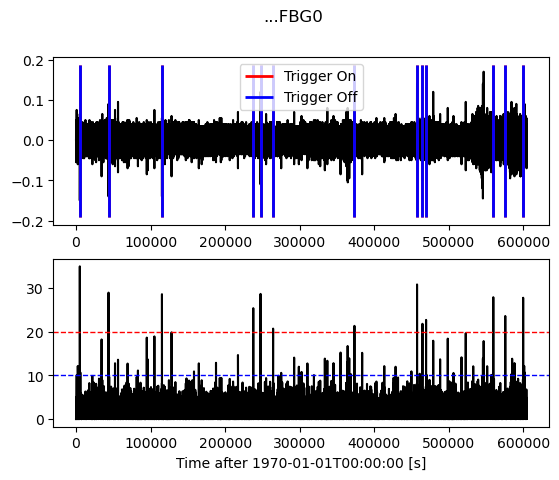

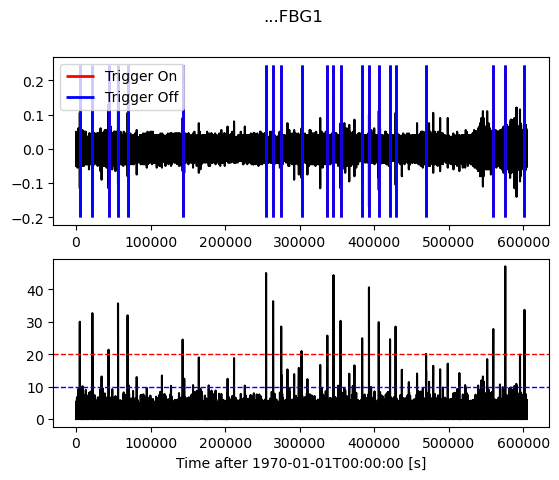

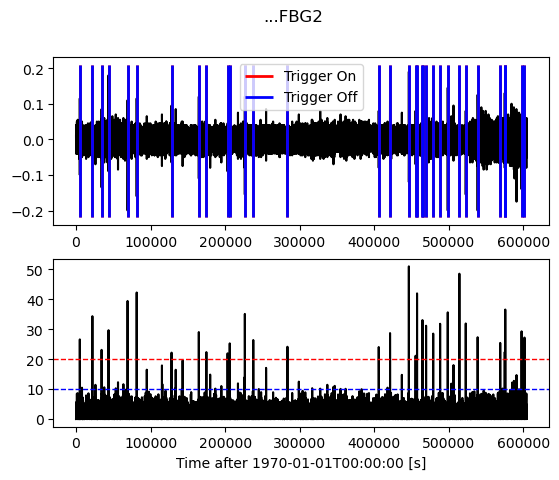

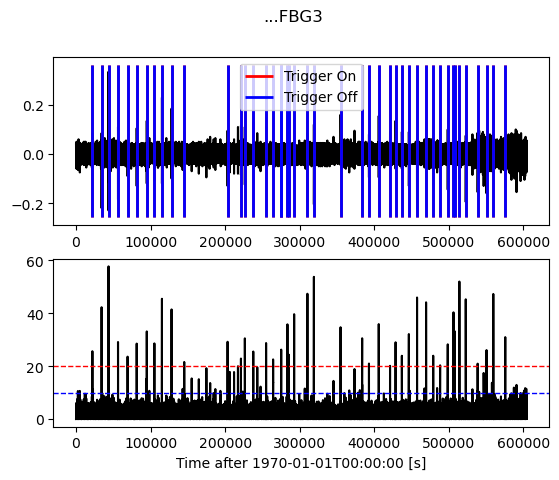

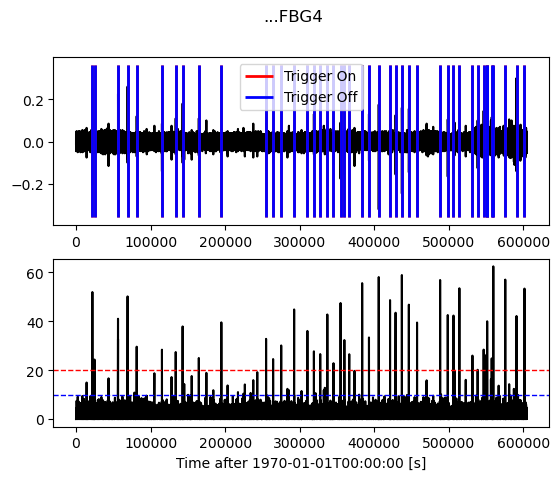

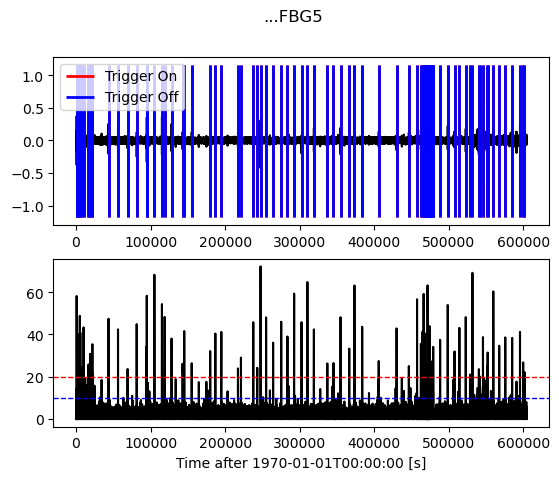

In [45]:
st = obspy.Stream() 
events = []
for i in range(grad.shape[0]):
    tr = obspy.Trace()
    tr.stats.sampling_rate = 0.5
    tr.stats.startdate = obspy.UTCDateTime(str(dtrend_october.Time.values[0]))
    tr.stats.channel = f'FBG{int(dtrend_october.FBG.values[i])}'
    tr.data = grad[i,:]*1000
    st.append(tr)     
    sta_lta = classic_sta_lta(tr.data, nsta=3, nlta=250)
    plot_trigger(tr, sta_lta, 20, 10)
    triggers_sta_lta = trigger_onset(sta_lta, 20, 10)
    for trigger in triggers_sta_lta :
        event = tr.data[trigger[0]-60:trigger[0]+60]
        events.append(event)



### Plot all the events

Text(0.5, 1.0, 'Detected events from 2024-10-19T11 to 2024-10-24\nCHANNEL 2, FBG 0 to 6 - Horizontal pads')

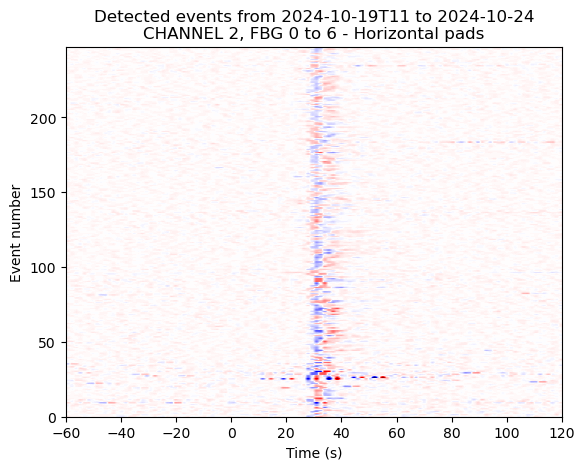

In [ ]:
plt.imshow(np.array(events), aspect='auto', cmap='seismic', extent=[-30*2, 60*2, 0, len(events)])
plt.xlabel('Time (s)')
plt.ylabel('Event number')
plt.title('Detected events from 2024-10-19T11 to 2024-10-24\nCHANNEL 3, FBG 0 to 6 - Horizontal pads')

### Aligning based on the CC

In [47]:
ref_event = events[0] - np.median(events[0])

In [48]:
_lags = []
_corr_2d = []
for i, event in enumerate(events) :
    correlation = signal.correlate(ref_event, event - np.mean(event), mode="full")
    lags = signal.correlation_lags(len(ref_event), len(event), mode="full")
    _corr_2d.append(correlation)
    lag = lags[np.argmax(correlation)]
    _lags.append(lag)

### Plotting the CCs

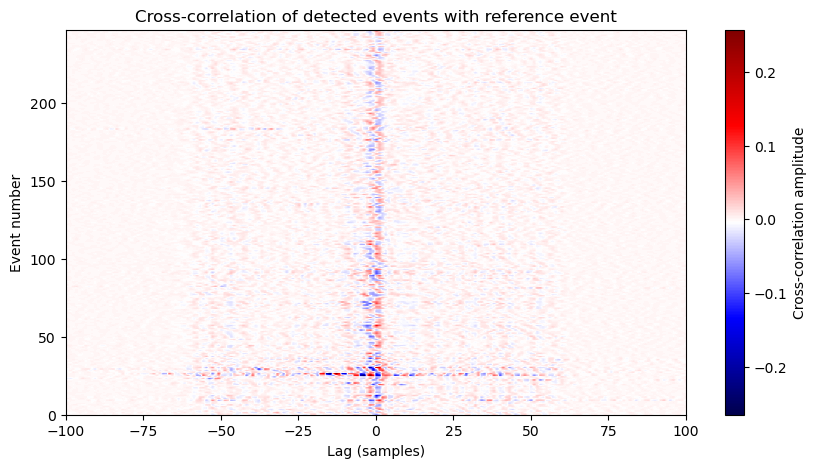

In [49]:
plt.figure(figsize=(10,5))
plt.imshow(_corr_2d, aspect='auto', cmap='seismic', extent=[min(lags), max(lags), 0, len(events)])
plt.colorbar(label='Cross-correlation amplitude')
plt.xlabel('Lag (samples)')
plt.ylabel('Event number')
plt.title('Cross-correlation of detected events with reference event')
plt.xlim(-100,100)
plt.show()

In [50]:
aligned_events = []
for i, event in enumerate(events) :
    lag = _lags[i]
    if lag > 0 :
        aligned_event = np.pad(event, (lag,0), mode='constant')[:len(ref_event)]
    elif lag < 0 :
        aligned_event = np.pad(event, (0,-lag), mode='constant')[-lag:len(ref_event)-lag]
    else :
        aligned_event = event
    aligned_events.append(aligned_event)

### Aligned events

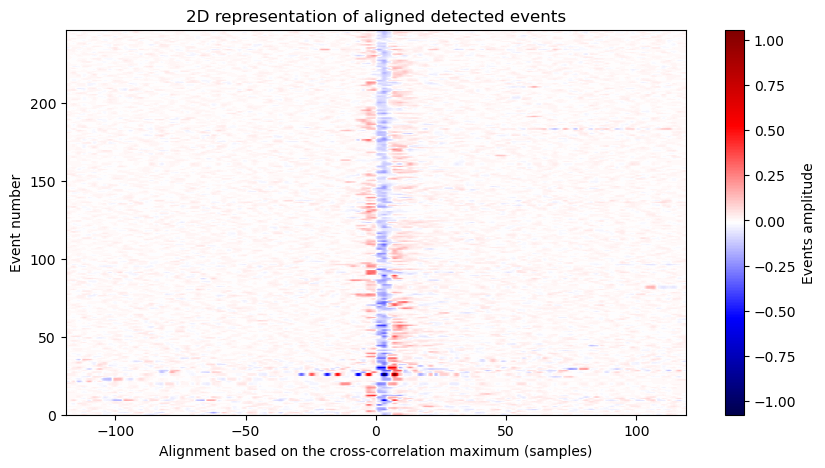

In [51]:
plt.figure(figsize=(10,5))
plt.imshow(aligned_events, aspect='auto', cmap='seismic', extent=[min(lags), max(lags), 0, len(events)])
plt.colorbar(label='Events amplitude')
plt.xlabel('Alignment based on the cross-correlation maximum (samples)')
plt.ylabel('Event number')
plt.title('2D representation of aligned detected events')
plt.show()

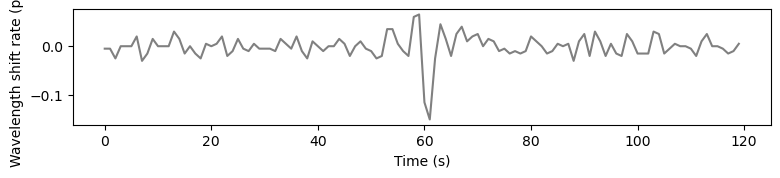

In [57]:
plt.figure(figsize=(9,1.5))
plt.plot(aligned_events[0],c='grey')
plt.xlabel('Time (s)')
plt.ylabel('Wavelength shift rate (pm/s)')
plt.show()

### Aligned CCs

In [52]:
_corr_2d = []
for i, event in enumerate(aligned_events) :
    correlation = signal.correlate(ref_event, event - np.mean(event), mode="full")
    lags = signal.correlation_lags(len(ref_event), len(event), mode="full")
    _corr_2d.append(correlation)

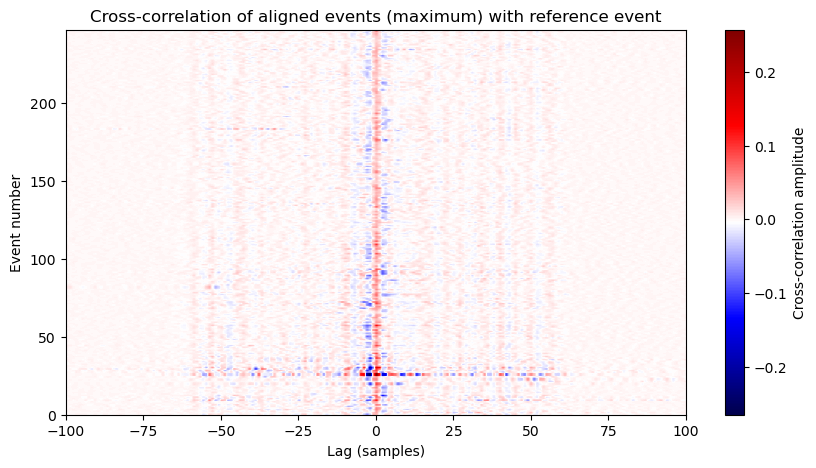

In [53]:
plt.figure(figsize=(10,5))
plt.imshow(_corr_2d, aspect='auto', cmap='seismic', extent=[min(lags), max(lags), 0, len(events)])
plt.colorbar(label='Cross-correlation amplitude')
plt.xlabel('Lag (samples)')
plt.ylabel('Event number')
plt.title('Cross-correlation of aligned events (maximum) with reference event')
plt.xlim(-100,100)
plt.show()